# Parcial 4 — Clasificación de clientes bancarios con representación visual y Deep Learning

Dataset **Bank Loan** (`credit_train.csv`). Objetivo: predecir si un préstamo será pagado (*Fully Paid*) o incumplido (*Charged Off*).

Flujo del notebook:
1. Carga, limpieza y exploración de datos.
2. Ingeniería de variables y normalización a [0, 1].
3. Dos representaciones visuales: **matriz de características** y **Gramian Angular Field (GAF)**.
4. Entrenamiento de 3 esquemas por representación: **desde cero**, **transfer learning** y **fine tuning** (`train.py`).
5. Comparación de métricas y selección del mejor modelo.
6. Prueba del modelo seleccionado sobre clientes nuevos (la aplicación completa está en `app.py`).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, display
from src.preprocessing import load_clean, engineer, labels, Preprocessor, FEATURES, CLASSES
from src.representations import make_images, REPRESENTATIONS
pd.set_option('display.max_columns', 30)
RETRAIN = False  # True para volver a entrenar los 6 modelos (≈30 min en GPU)

## 1. Carga y exploración

In [2]:
raw = pd.read_csv('data/credit_train.csv')
print('Forma original:', raw.shape)
df = load_clean('data/credit_train.csv')
print('Tras quitar filas vacías y duplicados por Loan ID:', df.shape)
df.head()

Forma original: (100514, 19)


Tras quitar filas vacías y duplicados por Loan ID: (81999, 19)


,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412.0,Short Term,709.0,1167493.0,8 years,Home Mortgage,Home Improvements,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328.0,Short Term,NaN,NaN,10+ years,Home Mortgage,Debt Consolidation,33295.98,21.1,8.0,35.0,0.0,229976.0,850784.0,0.0,0.0
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999.0,Short Term,741.0,2231892.0,8 years,Own Home,Debt Consolidation,29200.53,14.9,29.0,18.0,1.0,297996.0,750090.0,0.0,0.0
3,77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a,e777faab-98ae-45af-9a86-7ce5b33b1011,Fully Paid,347666.0,Long Term,721.0,806949.0,3 years,Own Home,Debt Consolidation,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220.0,Short Term,NaN,NaN,5 years,Rent,Debt Consolidation,20639.70,6.1,NaN,15.0,0.0,253460.0,427174.0,0.0,0.0


In [3]:
print(df['Loan Status'].value_counts(normalize=True).round(3))
df.isna().mean().sort_values(ascending=False).head(6).round(3)

Loan Status
Fully Paid     0.724
Charged Off    0.276
Name: proportion, dtype: float64


Months since last delinquent    0.544
Annual Income                   0.208
Credit Score                    0.208
Years in current job            0.043
Bankruptcies                    0.002
Tax Liens                       0.000
dtype: float64

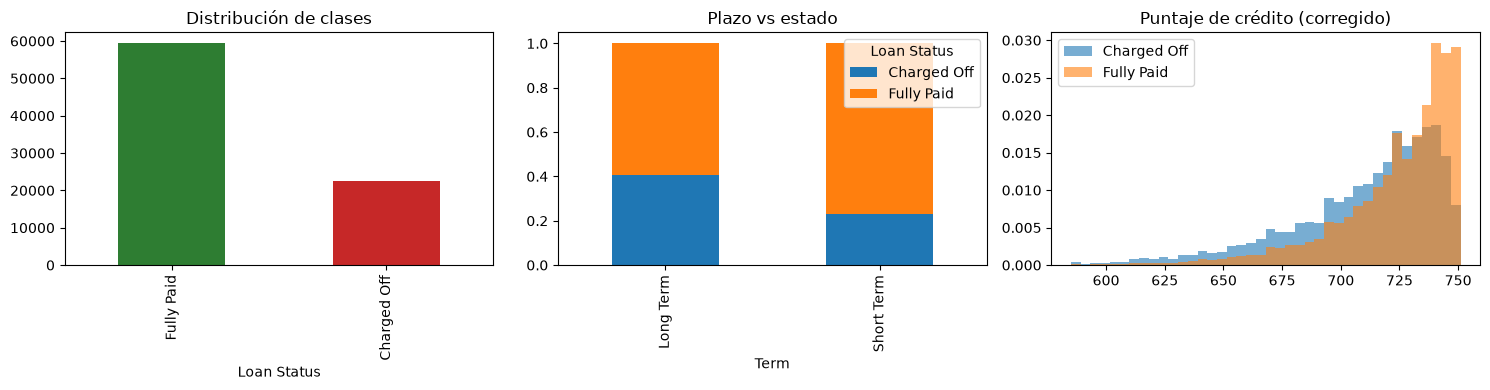

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df['Loan Status'].value_counts().plot.bar(ax=axes[0], color=['#2e7d32', '#c62828'], title='Distribución de clases')
pd.crosstab(df['Term'], df['Loan Status'], normalize='index').plot.bar(ax=axes[1], stacked=True, title='Plazo vs estado')
s = df['Credit Score'].where(df['Credit Score'] <= 850, df['Credit Score'] / 10)
for k, g in df.assign(s=s).groupby('Loan Status'): axes[2].hist(g.s.dropna(), bins=40, alpha=.6, density=True, label=k)
axes[2].set_title('Puntaje de crédito (corregido)'); axes[2].legend(); plt.tight_layout()

**Hallazgos de limpieza**
- 514 filas totalmente vacías y ~18.500 registros duplicados por `Loan ID` → se eliminan (quedan 81.999).
- `Current Loan Amount = 99999999` es un valor centinela → se trata como faltante.
- Algunos `Credit Score` están multiplicados por 10 (p. ej. 7120) → se dividen entre 10.
- Clases desbalanceadas (~72 % / 28 %) → pérdida ponderada por clase y métricas balanceadas (F1 macro, ROC-AUC).

## 2. Ingeniería de variables y normalización

In [5]:
feats = engineer(df)
y = labels(df)
prep = Preprocessor().fit(feats)
X = prep.transform(feats)
print(len(FEATURES), 'variables:', FEATURES)
print('Orden por clustering de correlación:', [FEATURES[i] for i in prep.order_])

27 variables: ['loan_amount', 'term_long', 'credit_score', 'annual_income', 'years_job', 'monthly_debt', 'credit_history_years', 'months_since_delinquent', 'never_delinquent', 'open_accounts', 'credit_problems', 'credit_balance', 'max_open_credit', 'bankruptcies', 'tax_liens', 'debt_to_income', 'credit_utilization', 'loan_to_income', 'income_missing', 'home_mortgage', 'home_rent', 'home_own', 'purpose_debt', 'purpose_home', 'purpose_business', 'purpose_other', 'purpose_personal']
Orden por clustering de correlación: ['income_missing', 'tax_liens', 'credit_problems', 'bankruptcies', 'purpose_business', 'purpose_personal', 'purpose_home', 'purpose_debt', 'purpose_other', 'months_since_delinquent', 'never_delinquent', 'loan_amount', 'loan_to_income', 'term_long', 'credit_score', 'credit_utilization', 'open_accounts', 'credit_balance', 'max_open_credit', 'annual_income', 'monthly_debt', 'debt_to_income', 'home_own', 'home_mortgage', 'home_rent', 'years_job', 'credit_history_years']


## 3. Representaciones visuales

- **Matriz de características:** las 27 variables (en [0,1]) se ordenan por clustering jerárquico de la correlación y se ubican en una cuadrícula 6×6 coloreada con *viridis* (celdas sobrantes en negro), escalada a 64×64.
- **Gramian Angular Field:** cada valor se convierte en ángulo φ = arccos(2x−1); la imagen 27×27 tiene 3 canales: GASF cos(φi+φj), GADF sin(φi−φj) y el producto xi·xj. Representa interacciones entre pares de variables.

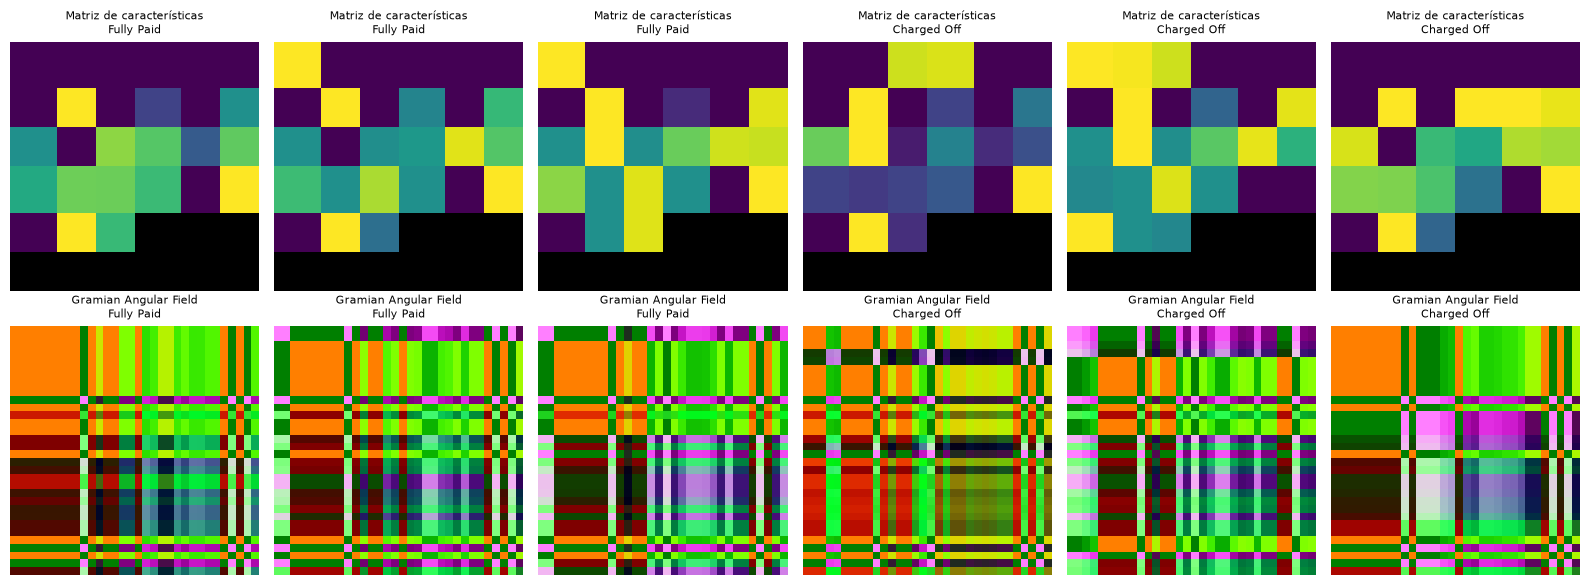

In [6]:
rng = np.random.default_rng(0)
idx = np.r_[rng.choice(np.where(y == 0)[0], 3, replace=False), rng.choice(np.where(y == 1)[0], 3, replace=False)]
xt = torch.tensor(X[idx])
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for r, rep in enumerate(REPRESENTATIONS):
    imgs = make_images(xt, rep, prep.order_)
    for c in range(6):
        axes[r, c].imshow(imgs[c].permute(1, 2, 0).numpy()); axes[r, c].axis('off')
        axes[r, c].set_title(f'{REPRESENTATIONS[rep]}\n{CLASSES[y[idx[c]]]}', fontsize=8)
plt.tight_layout()

## 4. Entrenamiento

`train.py` divide los datos de forma estratificada (70 % entrenamiento, 15 % validación, 15 % prueba) y entrena, para cada representación:

| Esquema | Arquitectura | Detalles |
|---|---|---|
| Desde cero | CNN propia: 3 bloques conv (32-64-128) + BN + MaxPool, GAP, Dropout 0.3 | AdamW lr 1e-3, 10 épocas |
| Transfer learning | ResNet-18 preentrenada en ImageNet, backbone congelado, se entrena solo la capa final | AdamW lr 1e-3, 8 épocas |
| Fine tuning | Parte del modelo de transfer learning; se descongelan `layer3`, `layer4` y la cabeza | AdamW lr 1e-4, 8 épocas |

Todos usan entropía cruzada ponderada por clase, scheduler coseno y parada temprana (paciencia 4) sobre ROC-AUC de validación. Como referencia se entrenan además una regresión logística y un HistGradientBoosting sobre los datos tabulares.

In [7]:
if RETRAIN:
    import train; train.main()
print(open('results_train_log.txt', encoding='utf-8').read()[-6000:])

_loss 0.6203 AUC 0.7193 F1m 0.4932 (39.0s)
  [feature_matrix/scratch] ep 05 loss 0.5991 val_loss 0.5973 AUC 0.7250 F1m 0.6353 (38.9s)
  [feature_matrix/scratch] ep 06 loss 0.5948 val_loss 0.6000 AUC 0.7207 F1m 0.6243 (38.8s)
  [feature_matrix/scratch] ep 07 loss 0.5926 val_loss 0.5892 AUC 0.7297 F1m 0.5898 (41.4s)
  [feature_matrix/scratch] ep 08 loss 0.5894 val_loss 0.5955 AUC 0.7274 F1m 0.6361 (51.6s)
  [feature_matrix/scratch] ep 09 loss 0.5865 val_loss 0.5878 AUC 0.7290 F1m 0.6092 (51.4s)
  [feature_matrix/scratch] ep 10 loss 0.5838 val_loss 0.5873 AUC 0.7296 F1m 0.6082 (51.3s)

=== feature_matrix__transfer ===
  [feature_matrix/transfer] ep 01 loss 0.7236 val_loss 0.6803 AUC 0.6224 F1m 0.5652 (7.2s)
  [feature_matrix/transfer] ep 02 loss 0.6784 val_loss 0.6783 AUC 0.6336 F1m 0.4284 (4.5s)
  [feature_matrix/transfer] ep 03 loss 0.6804 val_loss 0.6705 AUC 0.6372 F1m 0.5855 (4.5s)
  [feature_matrix/transfer] ep 04 loss 0.6736 val_loss 0.6648 AUC 0.6400 F1m 0.5797 (4.5s)
  [feature_ma

## 5. Comparación de modelos

In [8]:
res = pd.read_csv('results/metricas.csv')
cols = ['modelo', 'accuracy', 'balanced_accuracy', 'precision_co', 'recall_co', 'f1_co', 'f1_macro', 'roc_auc']
print('VALIDACIÓN'); display(res[res.split == 'val'][cols].sort_values('roc_auc', ascending=False).round(4))
print('PRUEBA'); display(res[res.split == 'test'][cols + ['params_entrenables', 'epocas', 'segundos']].sort_values('roc_auc', ascending=False).round(4))

VALIDACIÓN


,modelo,accuracy,balanced_accuracy,precision_co,recall_co,f1_co,f1_macro,roc_auc
4,feature_matrix__scratch,0.5998,0.6629,0.3907,0.8039,0.5259,0.5898,0.7297
2,baseline_hgb,0.6364,0.6624,0.4099,0.7203,0.5224,0.6145,0.7264
10,gaf__scratch,0.5207,0.6375,0.3547,0.8984,0.5086,0.5204,0.7223
8,feature_matrix__finetune,0.6170,0.6266,0.3850,0.6481,0.4830,0.5894,0.6845
0,baseline_logreg,0.6225,0.6277,0.3884,0.6393,0.4832,0.5930,0.6779
14,gaf__finetune,0.6533,0.6202,0.4052,0.5462,0.4653,0.6044,0.6751
6,feature_matrix__transfer,0.5924,0.6050,0.3633,0.6334,0.4618,0.5669,0.6429
12,gaf__transfer,0.5829,0.5964,0.3553,0.6266,0.4534,0.5581,0.6339


PRUEBA


,modelo,accuracy,balanced_accuracy,precision_co,recall_co,f1_co,f1_macro,roc_auc,params_entrenables,epocas,segundos
5,feature_matrix__scratch,0.6008,0.6664,0.3924,0.8130,0.5293,0.5914,0.7325,241442.0,10.0,432.4
3,baseline_hgb,0.6344,0.6611,0.4082,0.7208,0.5212,0.6128,0.7316,NaN,NaN,NaN
11,gaf__scratch,0.5278,0.6440,0.3589,0.9034,0.5137,0.5274,0.7244,241442.0,10.0,53.3
9,feature_matrix__finetune,0.6183,0.6321,0.3880,0.6628,0.4895,0.5923,0.6832,10494466.0,8.0,272.5
1,baseline_logreg,0.6223,0.6309,0.3897,0.6502,0.4873,0.5942,0.6800,NaN,NaN,NaN
15,gaf__finetune,0.6470,0.6160,0.3985,0.5468,0.4610,0.5993,0.6667,10494466.0,7.0,70.1
7,feature_matrix__transfer,0.5888,0.6036,0.3612,0.6366,0.4609,0.5643,0.6460,1026.0,8.0,38.9
13,gaf__transfer,0.5875,0.5991,0.3584,0.6251,0.4556,0.5618,0.6403,1026.0,8.0,40.6


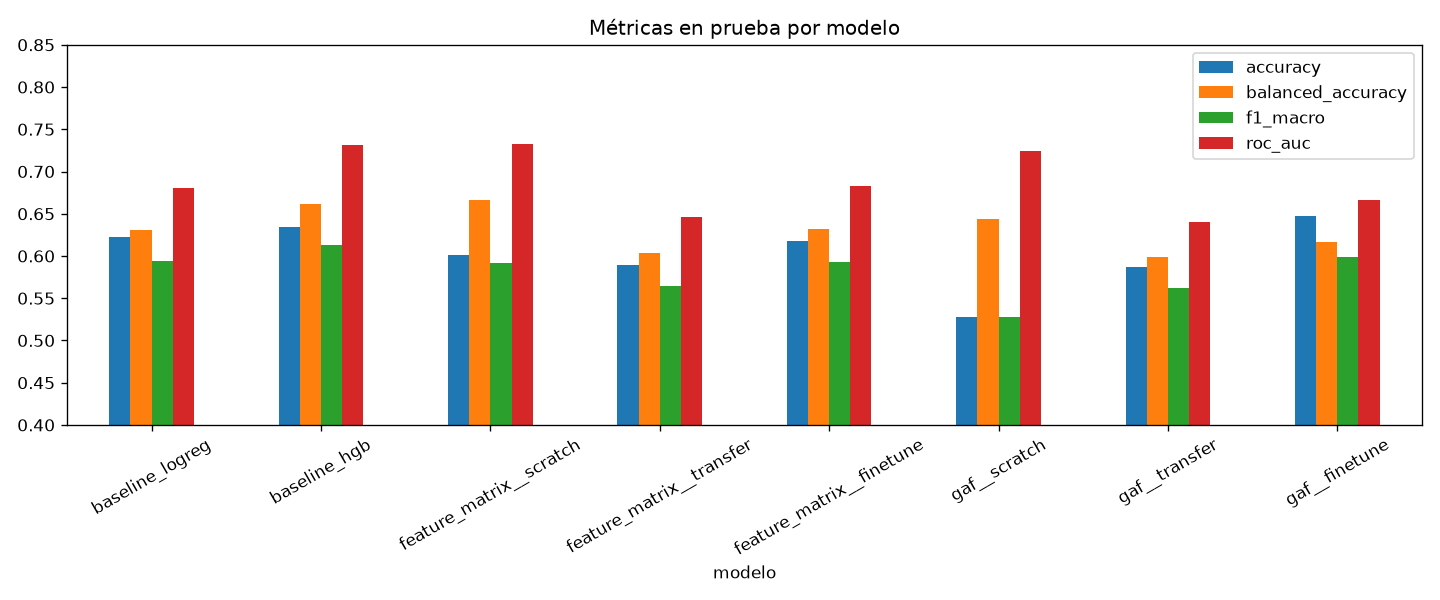

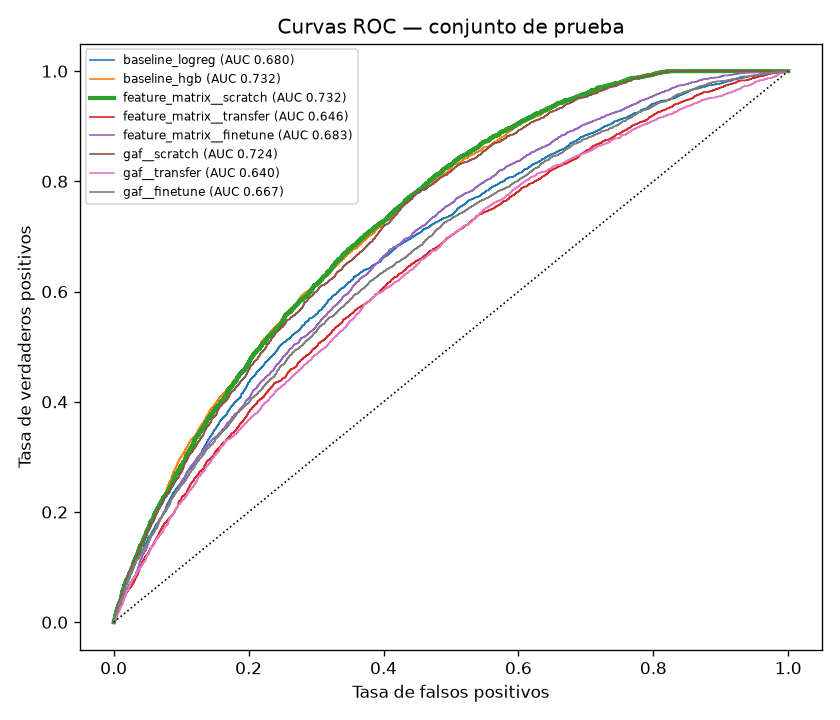

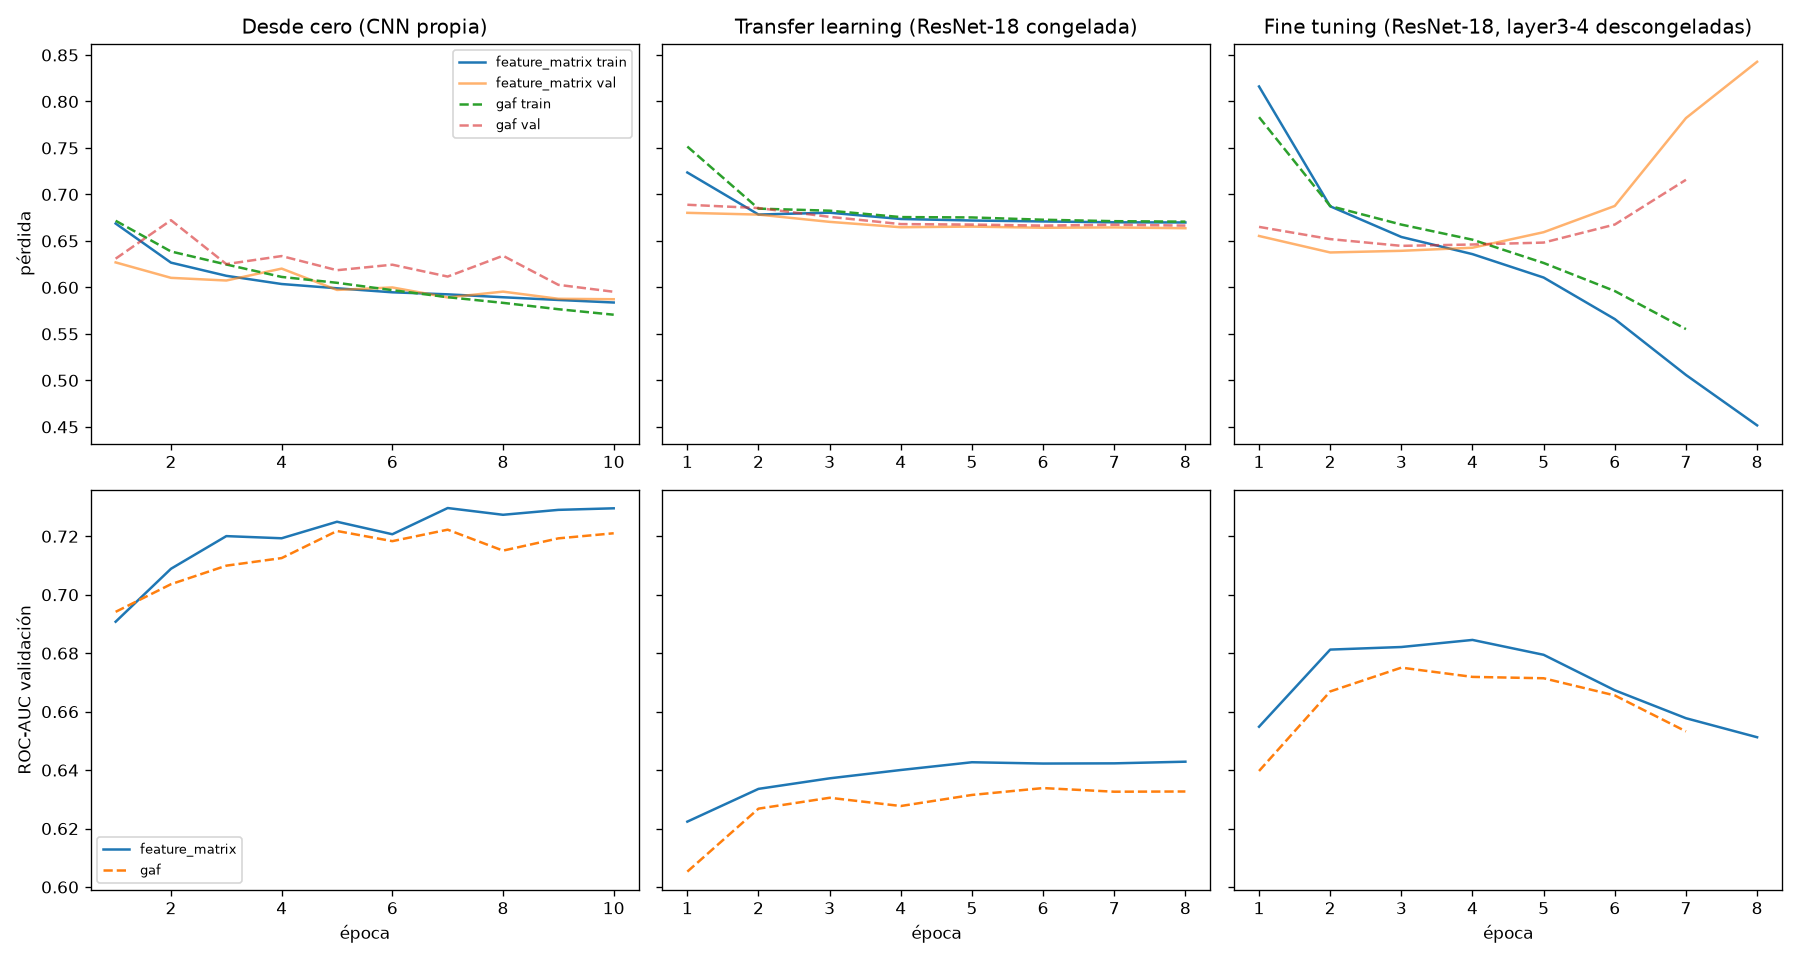

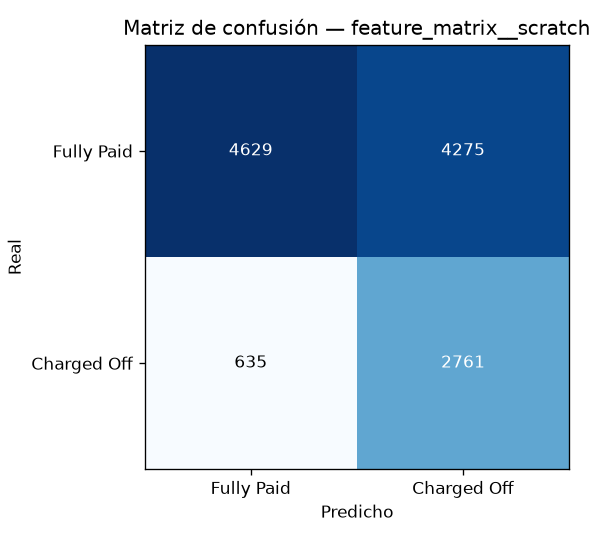

In [9]:
for f in ['comparacion_metricas', 'roc_prueba', 'curvas_entrenamiento', 'matriz_confusion_mejor']:
    display(Image(f'results/figures/{f}.png'))

In [10]:
info = json.load(open('models/model_info.json', encoding='utf-8'))
print('Modelo seleccionado:', info['key'], '| criterio:', info['selection'])
info['test_metrics']

Modelo seleccionado: feature_matrix__scratch | criterio: max ROC-AUC en validación


{'accuracy': 0.6008130081300813,
 'balanced_accuracy': 0.6664470091656904,
 'f1_macro': 0.5913886018955705,
 'f1_co': 0.5293328220858896,
 'recall_co': 0.8130153121319199,
 'precision_co': 0.39241046048891415,
 'roc_auc': 0.7324809253156559}

## 6. Uso del modelo seleccionado con clientes nuevos (`credit_test.csv`)

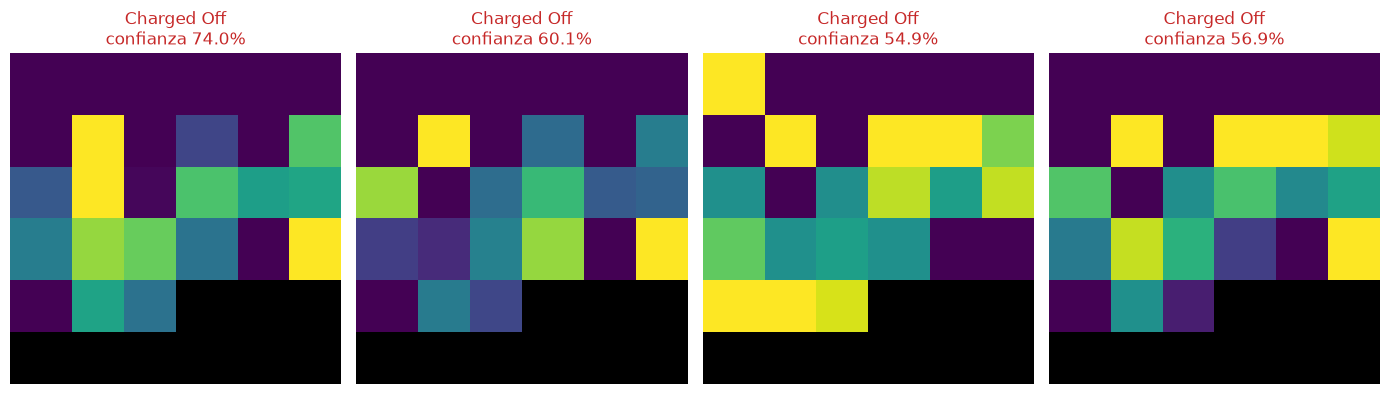

In [11]:
import joblib
from src.models import build_model
prep_m = joblib.load('models/preprocessor.joblib')
model = build_model(info['scheme'], pretrained=False)
model.load_state_dict(torch.load('models/best_model.pt', map_location='cpu')); model.eval()
new = pd.read_csv('data/credit_test.csv').dropna(subset=['Loan ID']).sample(4, random_state=1)
xn = torch.tensor(prep_m.transform(engineer(new)))
imgs = make_images(xn, info['representation'], np.array(info['order']))
with torch.no_grad(): p = torch.softmax(model(imgs), 1).numpy()
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for i, ax in enumerate(axes):
    k = p[i].argmax(); ax.imshow(imgs[i].permute(1, 2, 0).numpy()); ax.axis('off')
    ax.set_title(f'{CLASSES[k]}\nconfianza {p[i, k]:.1%}', color='#c62828' if k else '#2e7d32')
plt.tight_layout()

La aplicación interactiva se ejecuta con `streamlit run app.py`.